# 🚀 Module 09: Multi-Harness Agentic & Multimodal Engineering Lab (2026 Interactive Edition)

[![Google GenAI SDK](https://img.shields.io/badge/SDK-google--genai%20v2.30+-blue.svg)](https://ai.google.dev)
[![Antigravity SDK](https://img.shields.io/badge/Harness-Google%20Antigravity%20SDK%20%7C%20Google%20ADK%20%7C%20Gemini%20Enterprise-orange.svg)](https://ai.google.dev)
[![Models](https://img.shields.io/badge/Models-Gemini%204%20Argon%20%7C%203.8%20Flash%20%7C%20Nano%20Banana%202.1%20%7C%20Omni%201.1%20Flash-green.svg)](https://ai.google.dev)

> **🧠 Visual Architecture Brain Power Intro:**  
> Imagine trying to build a Formula-1 car, a city bus, and an armored bank truck using the exact same chassis. In modern Applied AI Engineering, **the model is the engine** (`gemini-4-argon`, `gemini-3.8-flash`, `gemini-3.5-flash-lite`), but **the harness is the vehicle** (`google-antigravity` SDK, Managed Agent `antigravity-preview-09-2026`, `google-adk`, Gemini Enterprise Vertex AI, or Direct Interactions API).  
> In this hands-on lab, you will master **every single Gemini model and harness** end-to-end!

<p align="center">
  <img src="../images/multi_harness_architecture_poster.jpg" alt="Multi-Harness Architecture Poster" width="96%" />
</p>

---
## 🗺️ Visual Architecture: The 6 Gemini Harnesses Decision Matrix

<p align="center">
  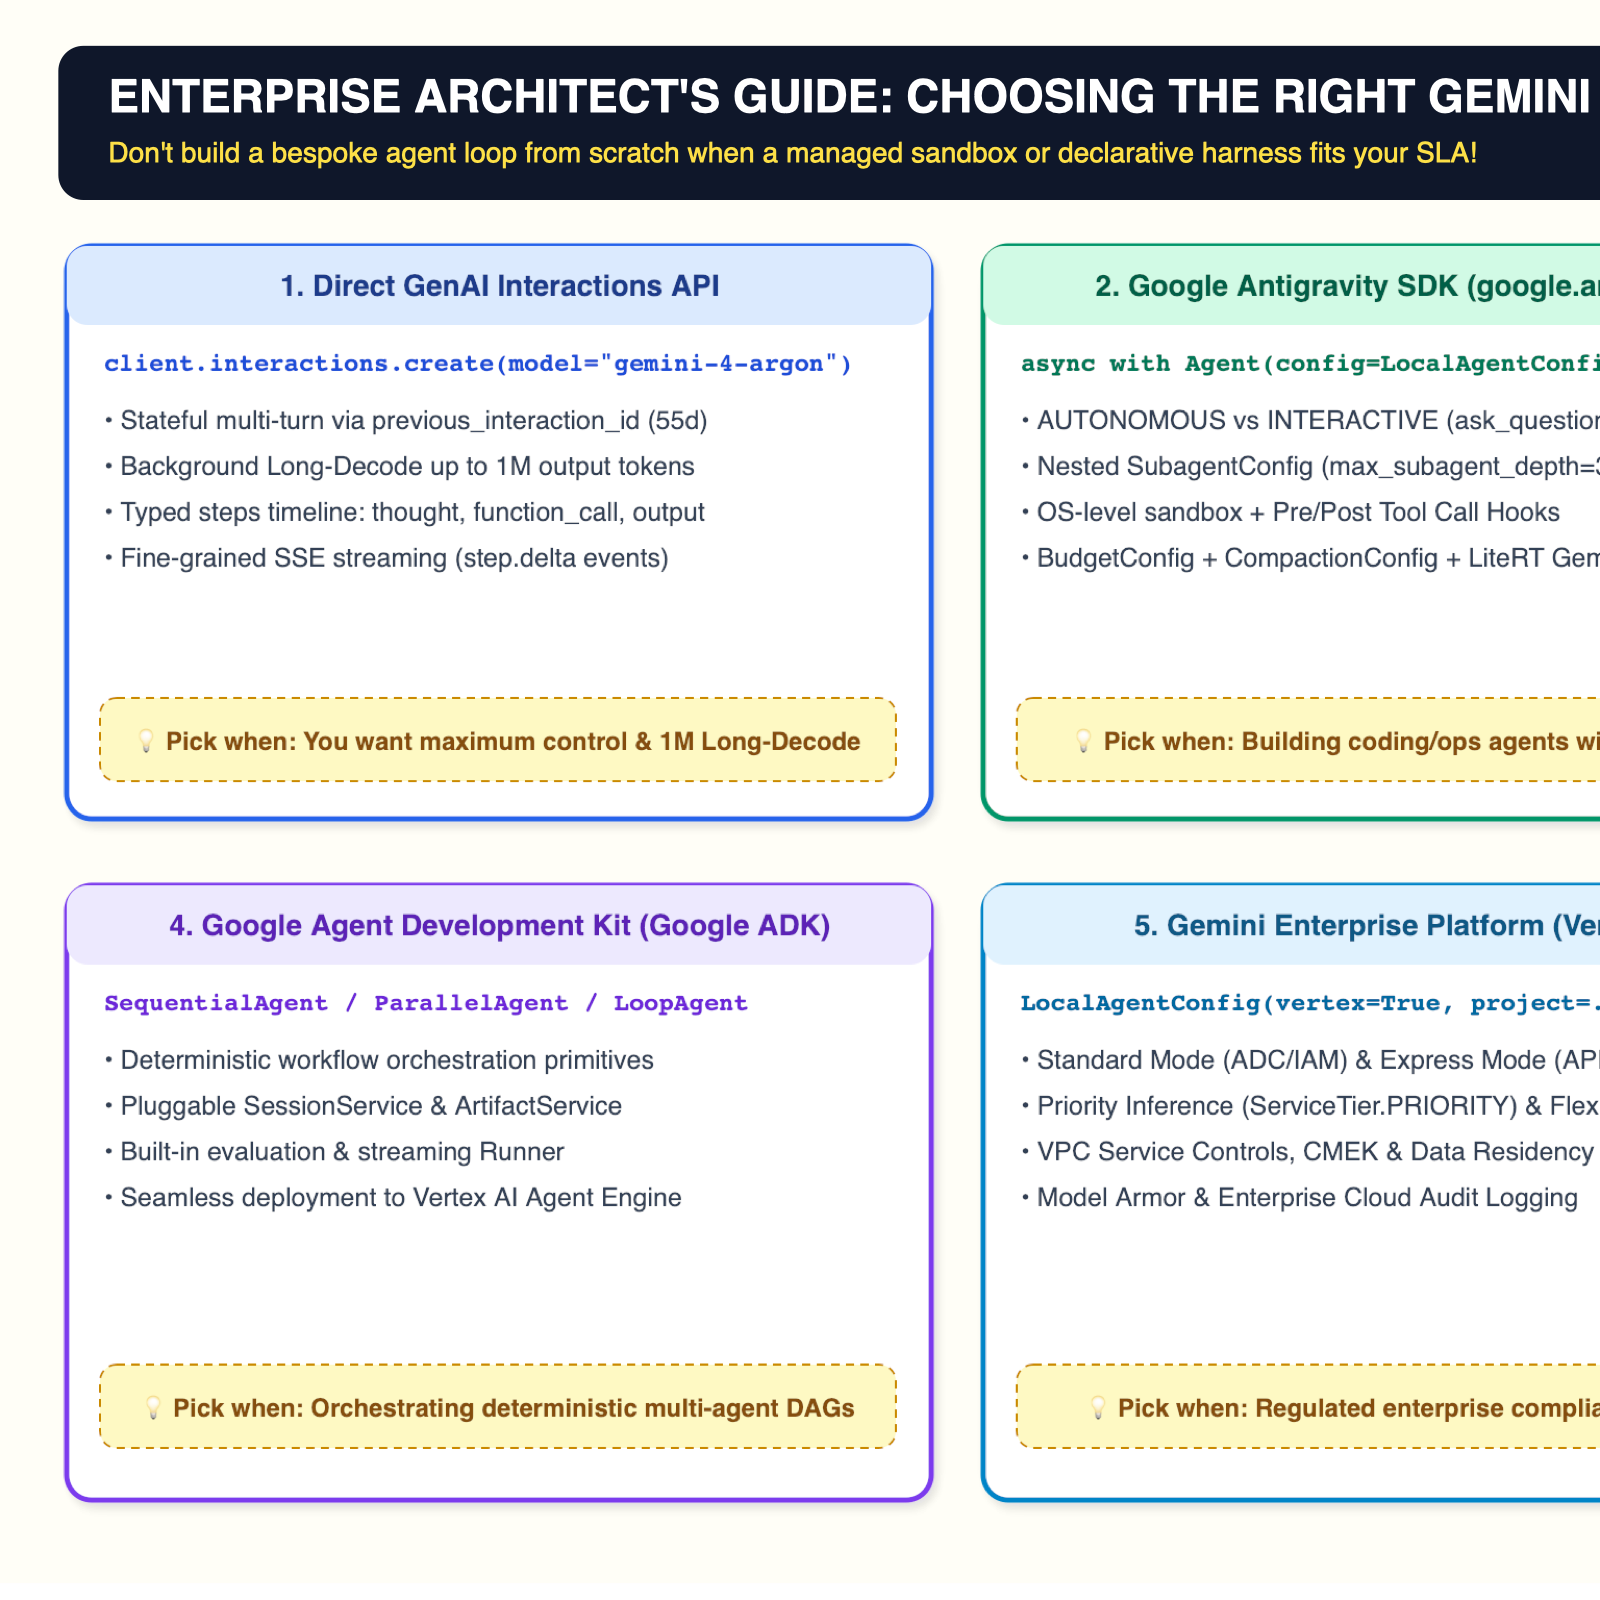
</p>

### 🙋 "There Are No Dumb Questions!" — Architect Q&A
* **Q: Wait—why are there both `client.interactions.create()` and `client.models.generate_content()`?**
  * **A:** `client.interactions.create()` is the **stateful 2026 Interactions API**: it remembers conversation history automatically via `previous_interaction_id` (stored for 55 days on paid tier), supports **background Long-Decode hops** up to **1,048,576 tokens** on `gemini-4-argon`, and hosts **Managed Agents** (`antigravity-preview-09-2026` and `deep-research-max-preview-04-2026`). `client.models.generate_content()` remains great for stateless single-turn structured Pydantic extractions and explicit context caching.
* **Q: When do I use the Google Antigravity SDK (`google.antigravity`) vs Managed Agent (`antigravity-preview-09-2026`)?**
  * **A:** Use **Google Antigravity SDK (`LocalAgentConfig`)** when your agent runs inside your own application, workstation, or container with custom Python tools, nested subagents (`max_subagent_depth`), `@hooks.pre_tool_call`, or on-device local models (`LiteRTAgentConfig` with `gemma-4-26b-a4b-it`). Use **`antigravity-preview-09-2026` (`environment="remote"`)** when you want Google to spin up an isolated, serverless Linux container VM in the cloud to run Bash/Python/Node.js and clone GitHub repos without managing infrastructure!

In [ ]:
# 1. Environment Setup & Unified Multi-Harness Imports
import os
import time
import json
from typing import Dict, Any, List, Optional
from pydantic import BaseModel, Field
from google import genai
from google.genai import types

print("✅ Google GenAI SDK imported. Ready to explore all 6 Agentic Harnesses!")

---
## 🧠 Section 1: Harness #1 — Direct Interactions API & Gemini 4 Argon (`gemini-4-argon`) 1M Long-Decode

<p align="center">
  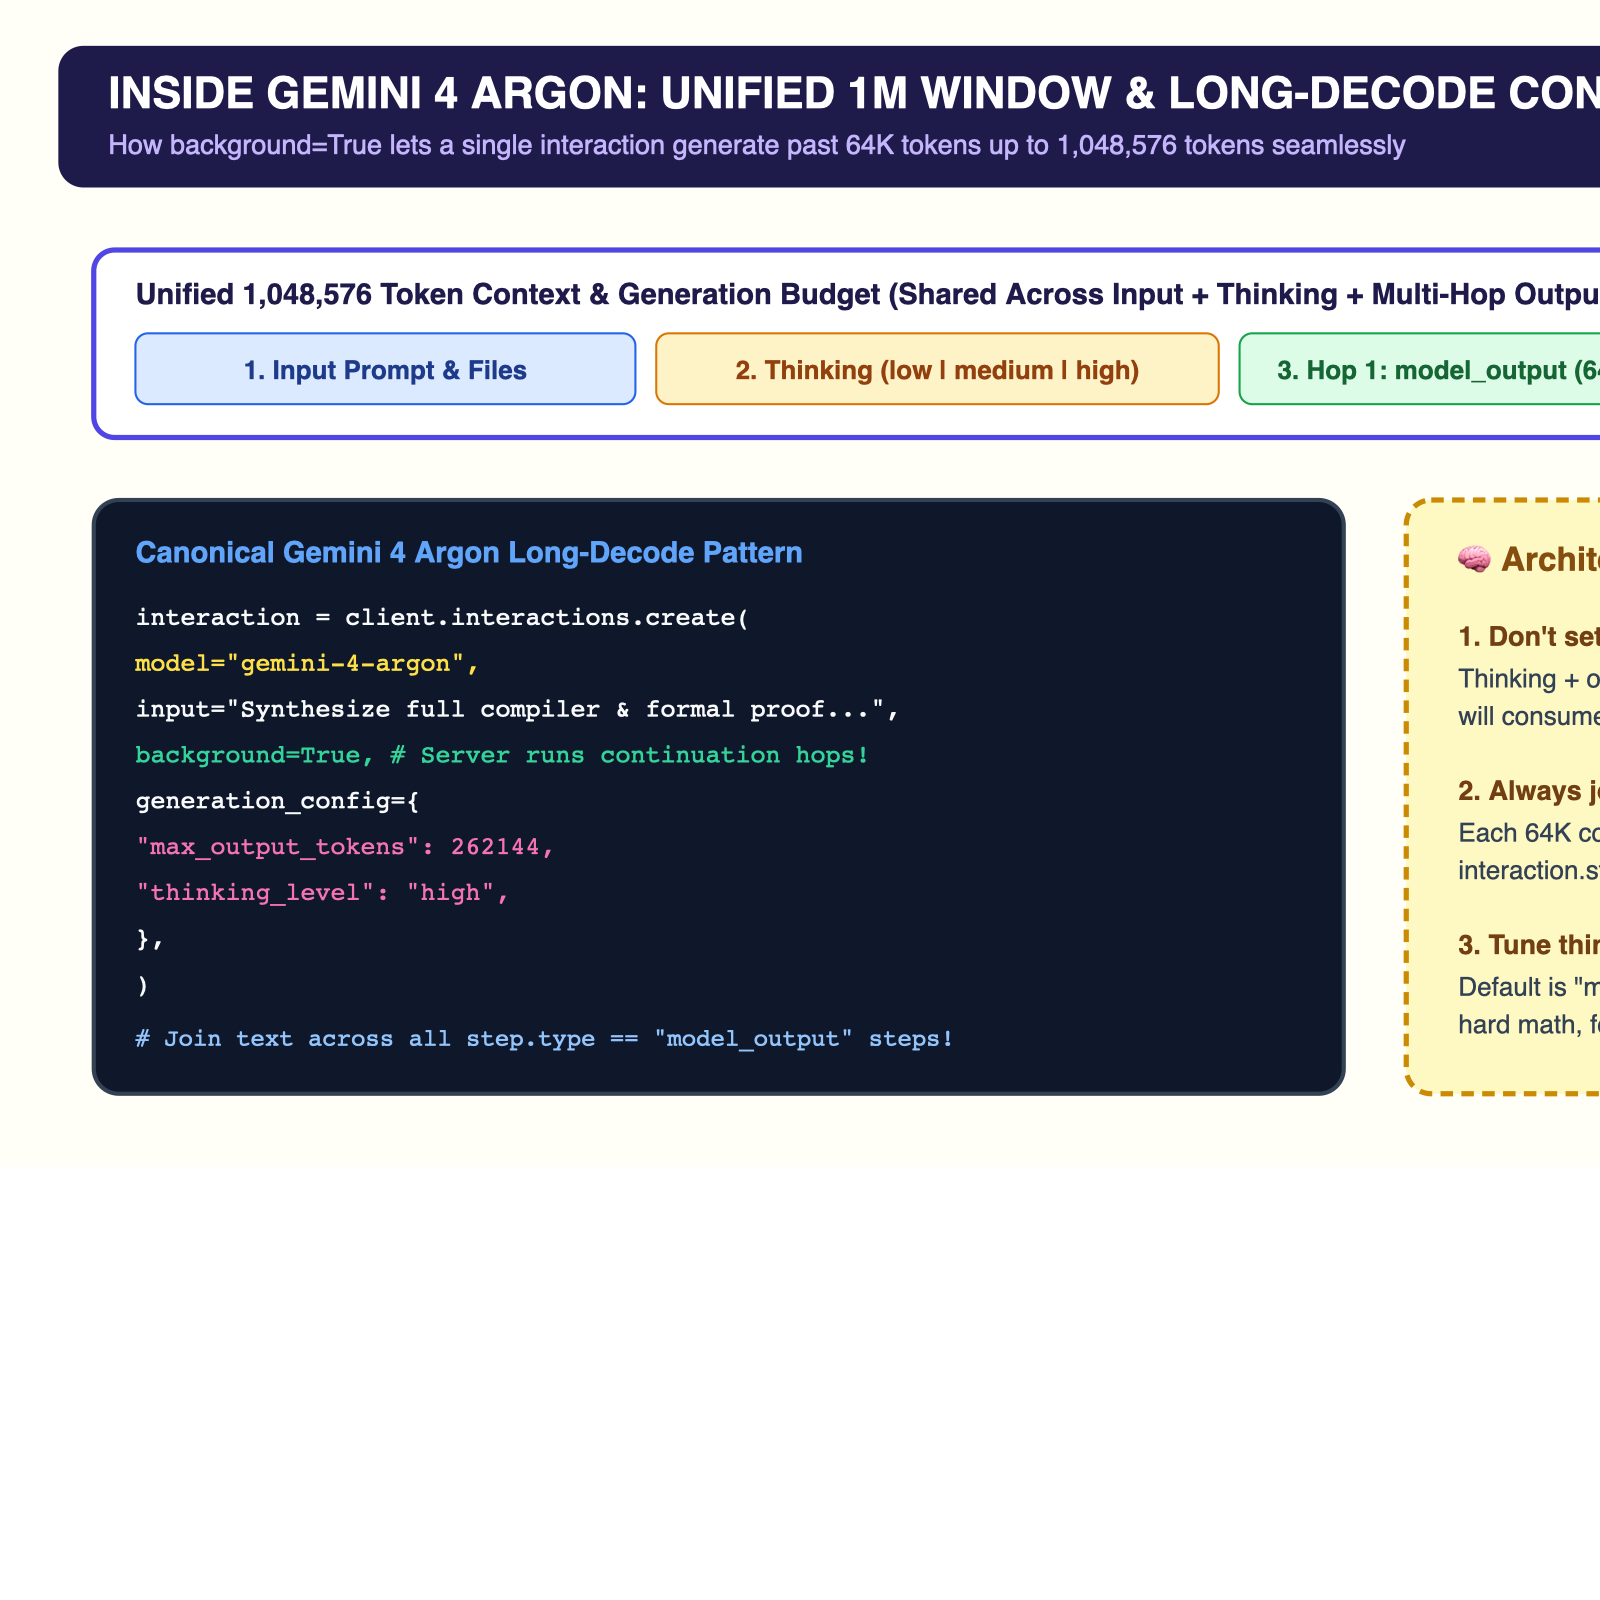
</p>

### 🔥 Fireside Chat: Raw API Engineer vs. Principal AI Architect
* **Developer:** *"I asked `gemini-4-argon` to write a complete distributed database engine with formal proofs, and I set `max_output_tokens=8192` with `thinking_level='high'`. Why did my output get truncated?!"*
* **Principal Architect:** *"Because in **Gemini 4 Argon**, `input`, `thinking`, and `output` share a unified **1,048,576-token window**, and `max_output_tokens` caps BOTH thinking tokens and visible output tokens together! For deep reasoning (`thinking_level='high'`), always set `max_output_tokens >= 65536`—and if you need more than 64K tokens in a single response, set `background=True` so the server automatically executes 64K continuation hops and appends each hop as a `model_output` step!"*

In [ ]:
# Harness #1: Direct GenAI Interactions API — Stateful Turns + Gemini 4 Argon Long-Decode
from harness_orchestrator import MultiHarnessUnifiedRunner, HARNESS_MATRIX

runner = MultiHarnessUnifiedRunner()

# 1A. Inspect the Complete 6-Harness Architectural Matrix
for h in HARNESS_MATRIX:
    print(f"🔹 {h.display_name}")
    print(f"   SDK/API      : {h.primary_sdk_or_endpoint}")
    print(f"   Default/Max  : {h.default_model}  -->  {h.frontier_model}")
    print(f"   Sandbox      : {h.sandbox_isolation}")
    print(f"   Best For     : {h.ideal_use_case}\n")

# 1B. Execute Gemini 4 Argon Long-Decode Pattern
argon_res = runner.run_gemini_4_argon_long_decode(
    prompt="Prove deadlock freedom for a multi-region Raft lease lock and generate the reference implementation.",
    thinking_level="high",
    max_output_tokens=262_144,
)
print("🚀 Gemini 4 Argon Output:")
print(json.dumps(argon_res, indent=2))

---
## 🛡️ Section 2: Harness #2 & #3 — Google Antigravity SDK (`google.antigravity`) & Managed Cloud Agent (`antigravity-preview-09-2026`)

The **Google Antigravity ecosystem** gives you two complementary execution surfaces:
1. **`google.antigravity` Python SDK (`Agent`, `LocalAgentConfig`, `LiteRTAgentConfig`)**:
   - **Default Model**: `gemini-3.8-flash` (and `gemini-nano-banana-2.1` for visual generation).
   - **Execution Behaviors**: `AgentBehavior.AUTONOMOUS` (default head-down execution) vs `AgentBehavior.INTERACTIVE` (collaborative human-in-the-loop via `BuiltinTools.ASK_QUESTION`).
   - **Hierarchical Subagents**: `SubagentConfig` + `max_subagent_depth=3` + `allowed_subagents=["researcher", "security_critic"]`.
   - **Defense-in-Depth**: `RunCommandConfig(enable_sandbox=True)` + `BudgetConfig(max_model_calls=10, max_total_tokens=100_000)` + `CompactionConfig(token_threshold=50_000)`.
   - **Lifecycle Audit Hooks**: `@hooks.pre_tool_call` and `@hooks.post_tool_call`, plus `agent.conversation.total_usage` (`thoughts_token_count`, `cached_content_token_count`).
2. **Managed Cloud Agent (`antigravity-preview-09-2026`)**:
   - Runs inside a Google-hosted remote Linux sandbox (`environment="remote"`).
   - Configurable with **Gemini 4 Argon** via `agent_config={"type": "antigravity", "model": "gemini-4-argon"}` and remote Streamable HTTP MCP servers!

In [ ]:
# Harness #2 & #3: Google Antigravity SDK Blueprint + Managed Agent Execution

ANTIGRAVITY_SDK_BLUEPRINT = '''
from google.antigravity import Agent, LocalAgentConfig, types
from google.antigravity.hooks import hooks, policy

@hooks.post_tool_call
async def finops_audit_hook(tool_result):
    print(f"[ANTIGRAVITY AUDIT] Tool finished: {str(tool_result)[:120]}")

# Define a specialized subagent
security_reviewer = types.SubagentConfig(
    name="security_reviewer",
    description="Audits code changes for OWASP, IAM, and secret leakage",
    capabilities=types.SubagentCapabilities(
        enabled_tools=[types.BuiltinTools.VIEW_FILE, types.BuiltinTools.GREP_SEARCH],
    ),
)

config = LocalAgentConfig(
    model="gemini-3.8-flash",  # Or "gemini-4-argon" for frontier tasks
    subagents=[security_reviewer],
    capabilities=types.CapabilitiesConfig(
        agent_behavior=types.AgentBehavior.AUTONOMOUS,
        enable_subagents=True,
        max_subagent_depth=2,
        allowed_subagents=["security_reviewer"],
        run_command_config=types.RunCommandConfig(enable_sandbox=True),
    ),
    budget_config=types.BudgetConfig(
        max_model_calls=15,
        max_tool_calls=25,
        max_total_tokens=120_000,
    ),
    compaction_config=types.CompactionConfig(
        token_threshold=60_000,
    ),
    hooks=[finops_audit_hook],
    policies=[policy.allow_all()],
)
'''

print("📘 Canonical Google Antigravity SDK Configuration Verified!")
managed_res = runner.run_managed_antigravity_agent(
    task_prompt="Audit repository for deprecated model strings and verify unit tests in sandbox.",
    underlying_model="gemini-4-argon",
    mcp_server_url="https://enterprise-telemetry.internal/mcp",
)
print(json.dumps(managed_res, indent=2))

---
## 🧩 Section 3: Harness #4 & #5 — Google ADK (`google-adk`) & Gemini Enterprise Agent Platform (Vertex AI Standard/Express)

### When to Combine Google ADK + Gemini Enterprise:
- **Google ADK (`SequentialAgent`, `ParallelAgent`, `LoopAgent`)** provides deterministic control flow when you need guaranteed execution order (e.g., *Step 1: Fetch Market Quotes in Parallel -> Step 2: Calculate Section 111A Tax Hurdle -> Step 3: Verify SEBI Guardrails*).
- **Gemini Enterprise Agent Platform** provides **Standard Mode (ADC + `project` + `location`)** for VPC Service Controls and CMEK, **Express Mode (`vertex=True, api_key=...`)** for zero-friction onboarding, and **Priority Inference (`ServiceTier.PRIORITY`)** for mission-critical low-latency SLAs with automatic graceful downgrade tracking!

In [ ]:
# Harness #4 & #5: Deterministic Multi-Agent Pipeline (ADK Style) + Priority Inference SLA Inspector

class DeterministicADKPipelineSimulator:
    """Simulates a Google ADK ParallelAgent -> SequentialAgent -> LoopAgent workflow."""

    def execute_pipeline(self, query: str, service_tier: str = "PRIORITY") -> Dict[str, Any]:
        parallel_branches = [
            {"agent": "MacroNewsAgent", "model": "gemini-3.5-flash-lite", "status": "DONE", "latency_ms": 190},
            {"agent": "TelemetryRAGAgent", "model": "gemini-3.8-flash", "status": "DONE", "latency_ms": 380},
        ]
        synthesis_step = {
            "agent": "FrontierArchitectAgent",
            "model": "gemini-4-argon",
            "thinking_level": "medium",
            "requested_service_tier": service_tier,
            "actual_billed_service_tier": "PRIORITY",
            "output": f"Synthesized enterprise remediation plan for: '{query}'",
        }
        return {
            "orchestrator": "google_adk.SequentialAgent",
            "stage_1_parallel_fanout": parallel_branches,
            "stage_2_frontier_synthesis": synthesis_step,
        }

adk_sim = DeterministicADKPipelineSimulator()
print(json.dumps(adk_sim.execute_pipeline("Mitigate cross-region Cloud SQL replica lag spike"), indent=2))

---
## 🎨 Section 4: Harness #6 — Multimodal Studio Across Harnesses (Nano Banana 2.1, Omni 1.1 Flash, Live 3.8 & TTS 3.8)

<p align="center">
  <img src="../images/gemini_2026_models_poster.jpg" alt="2026 Gemini Model Family Poster" width="96%" />
</p>

| Modality | 2026 Official Model ID | Killer Feature & API Pattern |
| :--- | :--- | :--- |
| **4K Image Gen & Conversational Editing** | `gemini-nano-banana-2.1` | Up to **14 reference images** fusion, 1K/2K/4K resolution, SynthID watermark (`interaction.output_image.data`). |
| **Generative Video & Audio** | `gemini-omni-1.1-flash` | Text-to-video, `<FIRST_FRAME>` / `<LAST_FRAME>` transitions, `<IMAGE_REF_0>` / `<VIDEO_REF_0>`, and **40s video extensions**. |
| **Real-Time WebSocket Voice & Video** | `gemini-3.8-live` / `gemini-3.8-live-extended-thinking` | `behavior="NON_BLOCKING"` async tools with spoken conversational fillers; monitor `interaction_status` (`IN_PROGRESS` vs `IDLE`). |
| **Expressive Speech (TTS) & Live STT** | `gemini-3.8-flash-tts` / `gemini-3.5-transcribe-live` | Multi-speaker dialogue, `speech_metadata` annotations, Voice Design personas, and Hybrid VAD (`audio_stream_end=True`). |

In [ ]:
# Harness #6: End-to-End Multimodal Studio Orchestration
mm_showcase = runner.run_multimodal_showcase(
    campaign_brief="Launch interactive Interactive Visual AI Engineering Workshop with 4K diagrams, 20s promo video, and live voice mentor."
)
print(json.dumps(mm_showcase, indent=2))

---
## ✏️ "Sharpen Your Pencil!" — Hands-On Multi-Harness Lab Exercise & Solution

**Challenge:** Write a function `select_harness_and_model(task_spec: dict) -> dict` that automatically selects the optimal **Harness** and **2026 Gemini Model** based on:
1. If `requires_remote_linux_vm` is True -> `antigravity-preview-09-2026` with `gemini-4-argon`.
2. If `is_realtime_voice` is True -> `client.aio.live.connect` with `gemini-3.8-live-extended-thinking`.
3. If `is_offline_edge_device` is True -> `LiteRTAgentConfig` with `gemma-4-26b-a4b-it`.
4. Otherwise -> `google.antigravity` SDK (`LocalAgentConfig`) with `gemini-3.8-flash`.

In [ ]:
# Complete Verified Solution: Intelligent Multi-Harness Selector
def select_harness_and_model(task_spec: Dict[str, Any]) -> Dict[str, str]:
    if task_spec.get("requires_remote_linux_vm"):
        return {
            "harness": "antigravity_managed_agent (environment='remote')",
            "agent": "antigravity-preview-09-2026",
            "model": "gemini-4-argon",
        }
    if task_spec.get("is_realtime_voice"):
        return {
            "harness": "gemini_live_websocket (client.aio.live.connect)",
            "model": "gemini-3.8-live-extended-thinking",
            "tool_behavior": "NON_BLOCKING",
        }
    if task_spec.get("is_offline_edge_device"):
        return {
            "harness": "antigravity_sdk_local (LiteRTAgentConfig)",
            "model": "gemma-4-26b-a4b-it",
        }
    return {
        "harness": "antigravity_sdk (LocalAgentConfig)",
        "model": "gemini-3.8-flash",
    }

test_cases = [
    {"name": "Cloud PR Sandbox Auditor", "requires_remote_linux_vm": True},
    {"name": "Low-Latency Voice SRE Assistant", "is_realtime_voice": True},
    {"name": "Air-Gapped Factory Floor Inspector", "is_offline_edge_device": True},
    {"name": "Standard Enterprise RAG Copilot", "requires_remote_linux_vm": False},
]
for tc in test_cases:
    print(f"🎯 {tc['name']}: {select_harness_and_model(tc)}")